#this is the rebuild of NB-05 finetune as v2

1 — Environment & Seed

First on Kaggle with Accelerator: GPU T4 x2 (or P100) and Internet: On.

In [11]:
!pip install -q "transformers>=4.48.0" accelerate

import os
import json
import time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    set_seed,
)

SEED = 42
set_seed(SEED)
print(f"PyTorch: {torch.__version__} | CUDA available: {torch.cuda.is_available()}")

PyTorch: 2.11.0+cu130 | CUDA available: True


2 — Configuration & Locked Route Codes

Update TRAIN_JSONL_PATH to match where you attached Shravan's train.jsonl in Kaggle's Input panel. Do not load test.jsonl or adversarial_sealed.jsonl in this notebook.

In [12]:
# 1. Input path (Kaggle Dataset containing ONLY Shravan's train.jsonl)
TRAIN_JSONL_PATH = "/kaggle/input/311-synthetic-v1/train.jsonl"  # <-- Update to your Kaggle input path

# 2. Choose your base encoder:
#    - "distilbert/distilroberta-base"  (fast baseline)
#    - "answerdotai/ModernBERT-base"    (stronger English encoder)
#    - "FacebookAI/xlm-roberta-base"    (optional multilingual candidate for ~18% non-English rows)
MODEL_ID = "distilbert/distilroberta-base"
SETUP_NAME = "finetuned_v1"

# 3. Output directories
SAVE_MODEL_DIR = f"/kaggle/working/models/{SETUP_NAME}"
RESULTS_DIR = "/kaggle/working/results/finetune"
os.makedirs(SAVE_MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

# 4. Locked 10 route codes (Interface 1 & Interface 2)
ROUTE_CODES = [
    "SW-BIN", "SW-MISS", "AN-DEAD", "AN-INJ", "RD-POT",
    "TR-TREE", "PS-PROP", "IL-DUMP", "EMERG", "OOS"
]
CODE_TO_ID = {c: i for i, c in enumerate(ROUTE_CODES)}
ID_TO_CODE = {i: c for i, c in enumerate(ROUTE_CODES)}

3 — Load train.jsonl & Grouped Train/Val Split

Splits train.jsonl (2,259 rows) 85/15 grouped by template_id so paraphrases of the same scenario never leak between training and validation.

In [13]:
import glob

matches = glob.glob("/kaggle/input/**/train.jsonl", recursive=True)
assert matches, f"train.jsonl not found! Attached inputs: {glob.glob('/kaggle/input/**/*', recursive=True)[:15]}"

TRAIN_JSONL_PATH = matches[0]
print(f"Loading: {TRAIN_JSONL_PATH}")

with open(TRAIN_JSONL_PATH, "r", encoding="utf-8") as f:
    df = pd.DataFrame([json.loads(line) for line in f if line.strip()])

# Keep only valid 10 route codes and map to integer IDs
df = df[df["service_code"].isin(ROUTE_CODES)].copy().reset_index(drop=True)
df["labels"] = df["service_code"].map(CODE_TO_ID)

# Grouped split by template_id (fallback to group/index if absent)
group_col = "template_id" if "template_id" in df.columns else ("group" if "group" in df.columns else None)
groups = df[group_col] if group_col else df.index

splitter = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
train_idx, val_idx = next(splitter.split(df, df["labels"], groups=groups))

train_df = df.iloc[train_idx].reset_index(drop=True)
val_df = df.iloc[val_idx].reset_index(drop=True)

print(f"Total rows: {len(df)} | Train: {len(train_df)} | Val: {len(val_df)} | Grouped by: {group_col}")
print("\nClass distribution (Train):")
print(train_df["service_code"].value_counts())
if "lang" in df.columns:
    print("\nLanguage split (Val):")
    print(val_df["lang"].value_counts())

Loading: /kaggle/input/datasets/johnmakela/311-train-data-20261120/train.jsonl
Total rows: 2259 | Train: 1916 | Val: 343 | Grouped by: template_id

Class distribution (Train):
service_code
SW-BIN     452
SW-MISS    291
PS-PROP    212
AN-DEAD    206
RD-POT     189
TR-TREE    163
OOS        153
AN-INJ     116
IL-DUMP    105
EMERG       29
Name: count, dtype: int64

Language split (Val):
lang
en           283
fr            29
franglais      8
es             8
pa             8
zh             7
Name: count, dtype: int64


#4 — Tokenize & Configure Trainer
Drops token_type_ids so the exact same code runs cleanly for both DistilRoBERTa and ModernBERT

In [14]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

def tokenize_batch(batch):
    tok = tokenizer(batch["message"], truncation=True, padding="max_length", max_length=256)
    tok.pop("token_type_ids", None)  # ModernBERT does not use token_type_ids
    return tok

train_ds = Dataset.from_pandas(train_df[["message", "labels"]]).map(tokenize_batch, batched=True)
val_ds = Dataset.from_pandas(val_df[["message", "labels"]]).map(tokenize_batch, batched=True)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_ID,
    num_labels=len(ROUTE_CODES),
    id2label=ID_TO_CODE,
    label2id=CODE_TO_ID,
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "macro_f1": f1_score(labels, preds, average="macro", zero_division=0),
    }

training_args = TrainingArguments(
    output_dir=f"{RESULTS_DIR}/checkpoints",
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    learning_rate=3e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=5,
    weight_decay=0.01,
    warmup_steps=0.1,  # replaces removed warmup_ratio in transformers v5+
    seed=SEED,
    data_seed=SEED,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    save_total_limit=2,
    fp16=torch.cuda.is_available(),
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)

Map:   0%|          | 0/1916 [00:00<?, ? examples/s]

Map:   0%|          | 0/343 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: distilbert/distilroberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


5 — Train & Export Weights for Nick

Trains the model, saves the best checkpoint to /kaggle/working/models/finetuned_v1/, and zips it to hand it off to Nick.

In [15]:
train_result = trainer.train()

# Save best model & tokenizer
trainer.save_model(SAVE_MODEL_DIR)
tokenizer.save_pretrained(SAVE_MODEL_DIR)
print(f"Saved best model to: {SAVE_MODEL_DIR}")

# Optional: Zip for easy download from Kaggle Output
!cd /kaggle/working/models && zip -rq finetuned_v1.zip finetuned_v1
print("Zipped checkpoint to /kaggle/working/models/finetuned_v1.zip")

# Optional: Push to Hugging Face Hub (uncomment if using HF_TOKEN in Kaggle Secrets)
# from kaggle_secrets import UserSecretsClient
# hf_token = UserSecretsClient().get_secret("HF_TOKEN")
# model.push_to_hub("your-hf-username/311-classifier-finetuned-v1", token=hf_token, private=True)
# tokenizer.push_to_hub("your-hf-username/311-classifier-finetuned-v1", token=hf_token, private=True)

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,3.843759,2.324081,0.670554,0.466820
2,1.591713,1.128351,0.848397,0.761056
3,0.902260,0.838771,0.883382,0.803250
4,0.614711,0.677031,0.903790,0.866448
5,0.462840,0.663997,0.900875,0.875631


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


... (3 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved best model to: /kaggle/working/models/finetuned_v1
Zipped checkpoint to /kaggle/working/models/finetuned_v1.zip


6 — Save Learning Curves, Confusion Matrix & Slice Diagnostics to results/finetune/

Saves all required curves and run metadata to results/finetune/, checks performance across lang (en vs. non-English) and difficulty, and reports Rule E3 confidence stats (confidence < 0.70 or top2 margin < 0.10).

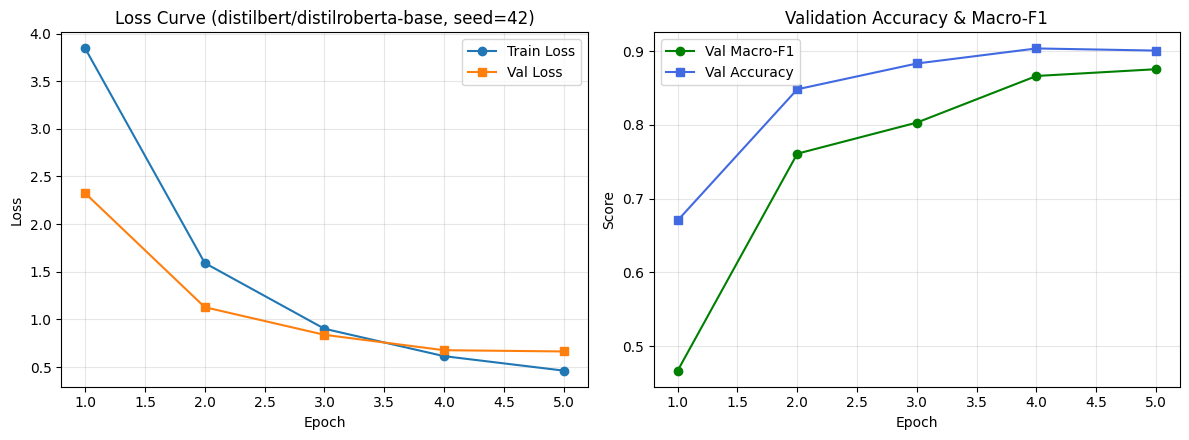

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


              precision    recall  f1-score   support

      SW-BIN       0.86      0.91      0.89        56
     SW-MISS       0.96      0.98      0.97        53
     AN-DEAD       0.94      0.85      0.89        39
      AN-INJ       0.93      0.93      0.93        27
      RD-POT       0.77      0.95      0.85        38
     TR-TREE       0.96      0.94      0.95        49
     PS-PROP       0.93      0.93      0.93        27
     IL-DUMP       0.86      1.00      0.92        12
       EMERG       1.00      0.44      0.62         9
         OOS       0.89      0.76      0.82        33

    accuracy                           0.90       343
   macro avg       0.91      0.87      0.88       343
weighted avg       0.91      0.90      0.90       343



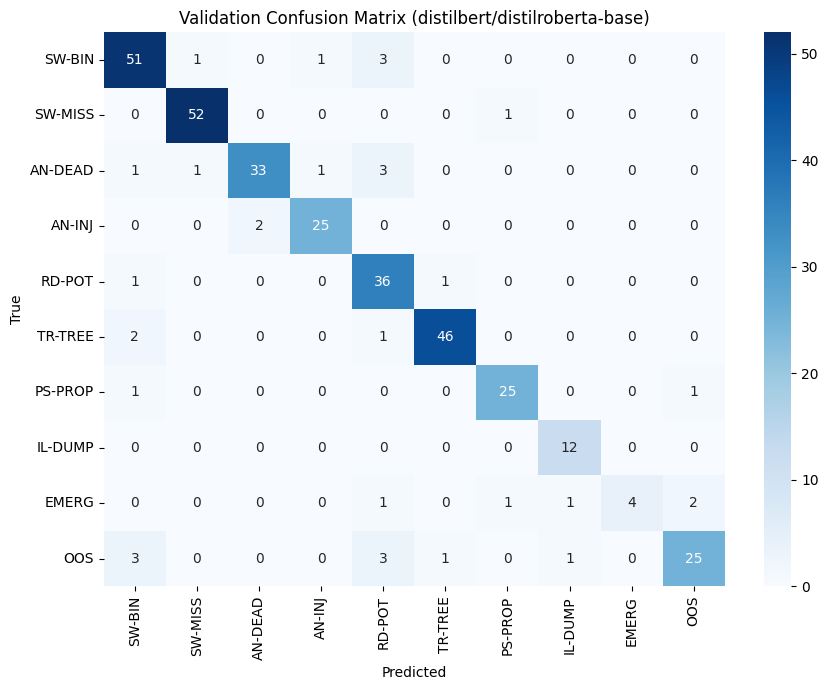


Accuracy by English vs Non-English:
            count      mean
is_english                 
False          60  0.566667
True          283  0.971731

Accuracy by Difficulty:
             count      mean
difficulty                  
adversarial     78  1.000000
easy           164  0.878049
hard           101  0.861386

Rule E3 (conf < 0.70 or margin < 0.10) triggered on 16.6% of val rows


In [16]:
# 1. Save training log & run config
history = pd.DataFrame(trainer.state.log_history)
history.to_csv(f"{RESULTS_DIR}/training_log.csv", index=False)

# 2. Plot Loss & Macro-F1 curves
train_loss = history.dropna(subset=["loss"])[["epoch", "loss"]]
eval_hist = history.dropna(subset=["eval_loss"])[["epoch", "eval_loss", "eval_macro_f1", "eval_accuracy"]]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(train_loss["epoch"], train_loss["loss"], marker="o", label="Train Loss")
axes[0].plot(eval_hist["epoch"], eval_hist["eval_loss"], marker="s", label="Val Loss")
axes[0].set_title(f"Loss Curve ({MODEL_ID}, seed={SEED})")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(eval_hist["epoch"], eval_hist["eval_macro_f1"], marker="o", color="green", label="Val Macro-F1")
axes[1].plot(eval_hist["epoch"], eval_hist["eval_accuracy"], marker="s", color="royalblue", label="Val Accuracy")
axes[1].set_title("Validation Accuracy & Macro-F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/learning_curves.png", dpi=200)
plt.show()

# 3. Validation predictions & probabilities
pred_out = trainer.predict(val_ds)
probs = torch.softmax(torch.tensor(pred_out.predictions), dim=-1).numpy()
sorted_probs = np.sort(probs, axis=-1)
top1_conf = sorted_probs[:, -1]
top2_margin = sorted_probs[:, -1] - sorted_probs[:, -2]
val_preds = np.argmax(probs, axis=-1)

val_df["pred_code"] = [ID_TO_CODE[i] for i in val_preds]
val_df["confidence"] = top1_conf
val_df["top2_margin"] = top2_margin
val_df["correct"] = (val_df["service_code"] == val_df["pred_code"]).astype(int)

# 4. Classification report & Confusion Matrix
print(classification_report(val_df["service_code"], val_df["pred_code"], labels=ROUTE_CODES, zero_division=0))

cm = confusion_matrix(val_df["service_code"], val_df["pred_code"], labels=ROUTE_CODES)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=ROUTE_CODES, yticklabels=ROUTE_CODES)
plt.title(f"Validation Confusion Matrix ({MODEL_ID})")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/confusion_matrix.png", dpi=200)
plt.show()

# 5. Diagnostic slices (Language, Difficulty, Rule E3 Calibration)
if "lang" in val_df.columns:
    val_df["is_english"] = val_df["lang"].eq("en")
    print("\nAccuracy by English vs Non-English:")
    print(val_df.groupby("is_english")["correct"].agg(["count", "mean"]))

if "difficulty" in val_df.columns:
    print("\nAccuracy by Difficulty:")
    print(val_df.groupby("difficulty")["correct"].agg(["count", "mean"]))

e3_triggered = ((val_df["confidence"] < 0.70) | (val_df["top2_margin"] < 0.10)).mean()
print(f"\nRule E3 (conf < 0.70 or margin < 0.10) triggered on {e3_triggered:.1%} of val rows")

# Save run summary JSON
run_config = {
    "setup": SETUP_NAME,
    "model_id": MODEL_ID,
    "seed": SEED,
    "train_rows": len(train_df),
    "val_rows": len(val_df),
    "val_accuracy": round(float(val_df["correct"].mean()), 4),
    "val_macro_f1": round(float(f1_score(val_df["service_code"], val_df["pred_code"], labels=ROUTE_CODES, average="macro", zero_division=0)), 4),
    "e3_trigger_rate": round(float(e3_triggered), 4),
}
with open(f"{RESULTS_DIR}/run_config.json", "w") as f:
    json.dump(run_config, f, indent=2)

7 — Interface 4 Smoke Test (Verify Exact Output for Nick)

Confirms the saved checkpoint loads cleanly and returns the exact Interface 4 dictionary shape (code, confidence, top2, setup, model, prompt_version, tokens_in, tokens_out, cost_usd, latency_ms).

In [17]:
device = "cuda" if torch.cuda.is_available() else "cpu"
inf_tok = AutoTokenizer.from_pretrained(SAVE_MODEL_DIR)
inf_model = AutoModelForSequenceClassification.from_pretrained(SAVE_MODEL_DIR).to(device).eval()

def classify_smoke_test(text: str) -> dict:
    t0 = time.perf_counter()
    with torch.no_grad():
        inputs = inf_tok(text, return_tensors="pt", truncation=True, max_length=256, padding=True)
        inputs.pop("token_type_ids", None)
        inputs = {k: v.to(device) for k, v in inputs.items()}
        probs = torch.softmax(inf_model(**inputs).logits, dim=-1).squeeze(0).cpu().tolist()
    ranked = sorted(enumerate(probs), key=lambda x: x[1], reverse=True)
    c1, p1 = ID_TO_CODE[ranked[0][0]], round(ranked[0][1], 4)
    c2, p2 = ID_TO_CODE[ranked[1][0]], round(ranked[1][1], 4)
    return {
        "code": c1,
        "confidence": p1,
        "top2": [{"code": c1, "confidence": p1}, {"code": c2, "confidence": p2}],
        "setup": SETUP_NAME,
        "model": MODEL_ID,
        "prompt_version": "ft-v1",
        "tokens_in": 0,
        "tokens_out": 0,
        "cost_usd": 0.0,
        "latency_ms": int((time.perf_counter() - t0) * 1000),
    }

for sample in [
    "The lid on my green bin cracked. 14 Alder Lane.",
    "There is a downed live wire sparking on Main Street!",
    "Where do I pay my property taxes?",
]:
    print(json.dumps(classify_smoke_test(sample), indent=2))

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

{
  "code": "SW-BIN",
  "confidence": 0.9873,
  "top2": [
    {
      "code": "SW-BIN",
      "confidence": 0.9873
    },
    {
      "code": "EMERG",
      "confidence": 0.0021
    }
  ],
  "setup": "finetuned_v1",
  "model": "distilbert/distilroberta-base",
  "prompt_version": "ft-v1",
  "tokens_in": 0,
  "tokens_out": 0,
  "cost_usd": 0.0,
  "latency_ms": 84
}
{
  "code": "EMERG",
  "confidence": 0.5055,
  "top2": [
    {
      "code": "EMERG",
      "confidence": 0.5055
    },
    {
      "code": "AN-DEAD",
      "confidence": 0.1365
    }
  ],
  "setup": "finetuned_v1",
  "model": "distilbert/distilroberta-base",
  "prompt_version": "ft-v1",
  "tokens_in": 0,
  "tokens_out": 0,
  "cost_usd": 0.0,
  "latency_ms": 6
}
{
  "code": "OOS",
  "confidence": 0.8864,
  "top2": [
    {
      "code": "OOS",
      "confidence": 0.8864
    },
    {
      "code": "SW-MISS",
      "confidence": 0.0291
    }
  ],
  "setup": "finetuned_v1",
  "model": "distilbert/distilroberta-base",
  "prompt_ver